# Perturbability vs. PANSS: direct correlation

Validates perturbability as a clinically relevant measure on its own terms, before bringing the PANSS model into it (see `perturbability_model_performance.ipynb` for that half).

Per subject, reduces each 100-region perturbability map to a single scalar — the **most significant perturbation**:
- `max(p2o)`: the strongest perturbation-to-origin across regions.
- `min(p2h)`: the strongest perturbation-to-healthy across regions (most negative = furthest from healthy).

Then correlates each against the subject's actual PANSS score, pooling AP + NAP.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr

## Load data

In [2]:
# Perturbability maps: per-region (100,) scores per subject, keyed by group then subject index
p2h_maps = np.load("./data/p2h_maps.pkl", allow_pickle=True)
p2o_maps = np.load("./data/p2o_maps.pkl", allow_pickle=True)

# clinical scores
clinical = np.load('./data/HCP_early_psychosis_clinical_scores.npz')
panss_AP = clinical["panss_AP"]
panss_NAP = clinical["panss_NAP"]

## Per-subject perturbability summary (pooled AP + NAP)

In [3]:
def build_perturbability_summary():
    """
    Per-subject max(p2o) and min(p2h) across regions ("most significant
    perturbation"), pooled AP-then-NAP, aligned with PANSS and with the
    subject ordering used by the Ftau model in perturbability_model_performance.ipynb.
    """
    max_p2o_list, min_p2h_list, y_list = [], [], []

    for group, panss in (("AP", panss_AP), ("NAP", panss_NAP)):
        for idx in range(len(panss)):
            max_p2o_list.append(np.max(p2o_maps[group][idx]))
            min_p2h_list.append(np.min(p2h_maps[group][idx]))
            y_list.append(panss[idx])

    max_p2o = np.array(max_p2o_list)
    min_p2h = np.array(min_p2h_list)
    y = np.array(y_list)

    valid_mask = ~np.isnan(y)
    return max_p2o[valid_mask], min_p2h[valid_mask], y[valid_mask]


max_p2o, min_p2h, y = build_perturbability_summary()
print(f"N = {len(y)} subjects")

N = 92 subjects


## Correlate with PANSS

max(p2o) vs PANSS: r = 0.0921, p = 0.3824
min(p2h) vs PANSS: r = -0.1287, p = 0.2214


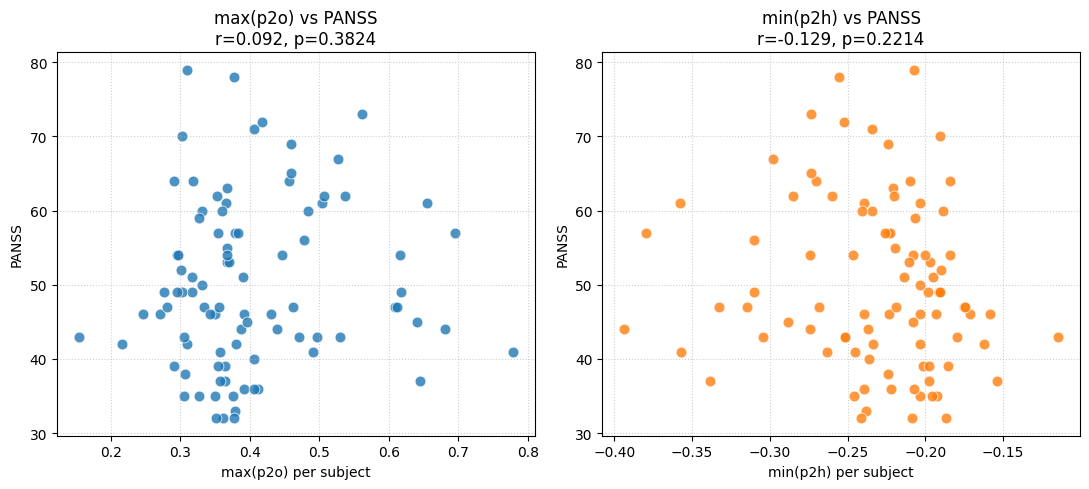

In [4]:
r_p2o, p_p2o = pearsonr(max_p2o, y)
r_p2h, p_p2h = pearsonr(min_p2h, y)

print(f"max(p2o) vs PANSS: r = {r_p2o:.4f}, p = {p_p2o:.4f}")
print(f"min(p2h) vs PANSS: r = {r_p2h:.4f}, p = {p_p2h:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

sns.scatterplot(x=max_p2o, y=y, ax=axes[0], color='#1f77b4', s=60, alpha=0.8)
axes[0].set_title(f'max(p2o) vs PANSS\nr={r_p2o:.3f}, p={p_p2o:.4f}')
axes[0].set_xlabel('max(p2o) per subject')
axes[0].set_ylabel('PANSS')
axes[0].grid(True, linestyle=':', alpha=0.6)

sns.scatterplot(x=min_p2h, y=y, ax=axes[1], color='#ff7f0e', s=60, alpha=0.8)
axes[1].set_title(f'min(p2h) vs PANSS\nr={r_p2h:.3f}, p={p_p2h:.4f}')
axes[1].set_xlabel('min(p2h) per subject')
axes[1].set_ylabel('PANSS')
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()